<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Histogram**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab, you will perform the following:


- Visualize the distribution of data using histograms.

- Visualize relationships between features.

- Explore data composition and comparisons.


## Demo: Working with database


#### Download the database file.


In [1]:
!wget -O survey-data.sqlite https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 211415040 (202M) [application/octet-stream]
Saving to: ‘survey-data.sqlite’

survey-data.sqlite  100%[===================>] 201.62M  19.6MB/s    in 10s     

2026-10-16 02:50:40 (20.1 MB/s) - ‘survey-data.sqlite’ saved [211415040/211415040]


#### Install the required libraries and import them


In [2]:
!pip install pandas

In [3]:
!pip install matplotlib

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

#### Connect to the SQLite database


In [5]:
conn = sqlite3.connect('survey-data.sqlite')

## Demo: Basic SQL queries

**Demo 1: Count the number of rows in the table**


In [6]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)


   COUNT(*)
0     65437

**Demo 2: List all tables**


In [7]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


**Demo 3: Group data by age**


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)


                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568

## Hands-on Lab: Visualizing Data with Histograms


### 1. Visualizing the distribution of data (Histograms)


**1.1 Histogram of `CompTotal` (Total Compensation)**


Objective: Plot a histogram of `CompTotal` to visualize the distribution of respondents' total compensation.


Text(0.5, 1.0, " Distribution of Respondents' Total Compensation.")

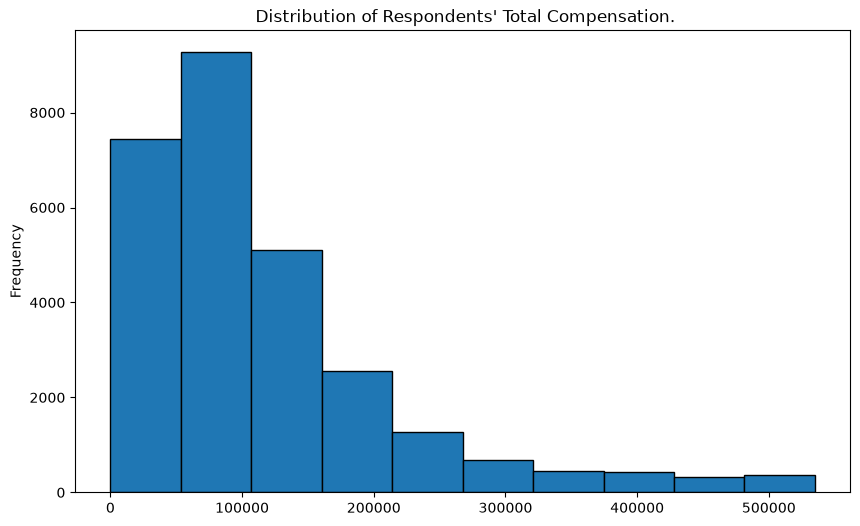

In [9]:
## Write your code here
query1  = """SELECT CompTotal, Age,TimeSearching,DatabaseWantToWorkWith,RemoteWork,JobSat,YearsCodePro FROM main"""
df_hist = pd.read_sql(query1, conn)
q1 = df_hist['CompTotal'].quantile(0.25)
q3 = df_hist['CompTotal'].quantile(0.75)
iqr = q3 - q1
low_bound = q1 - (1.5 * iqr)
high_bound =  q3 + (1.5 * iqr)
filtered = df_hist[(df_hist['CompTotal'] >= q1 - 1.5*iqr) & (df_hist['CompTotal'] <= q3 + 1.5*iqr)]
filtered['CompTotal'].plot(kind='hist', edgecolor='black',figsize=(10, 6))
plt.title(" Distribution of Respondents' Total Compensation.")

**1.2 Histogram of YearsCodePro (Years of Professional Coding Experience)**


Objective: Plot a histogram of `YearsCodePro` to analyze the distribution of coding experience among respondents.


In [10]:
## Write your code here
query2 = """SELECT YearsCodePro FROM main"""
df_hist2 = pd.read_sql(query2, conn)
df_hist2.value_counts()

YearsCodePro      
2                     4168
3                     4093
5                     3526
10                    3251
4                     3215
Less than 1 year      2856
6                     2843
1                     2639
8                     2549
7                     2517
12                    1777
15                    1635
20                    1549
9                     1493
11                    1312
13                    1127
14                    1082
25                     998
16                     946
18                     867
17                     814
30                     689
24                     632
19                     516
22                     492
23                     448
26                     426
27                     380
21                     380
28                     342
35                     285
29                     196
32                     194
40                     194
34                     169
38                     134
33       

Objective: Use histograms to compare the distribution of CompTotal across different Age groups.


In [11]:
## Write your code here
mapping = {
    'Less than 1 year': 0.5,  
    'More than 50 years': 51 
}

df_hist2['YearsCodePro_Numeric'] = (
    df_hist2['YearsCodePro']
    .replace(mapping)
    .astype(float)
)

Objective: Use histograms to explore the distribution of `TimeSearching` (time spent searching for information) for respondents across different age groups.


Text(0.5, 0, 'Experience')

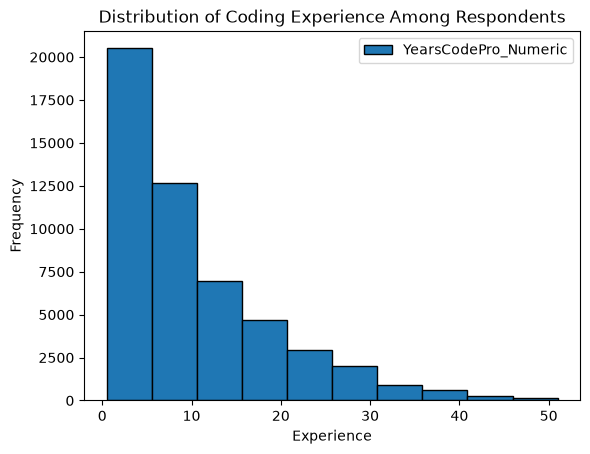

In [12]:
## Write your code here
df_hist2.plot(kind='hist',edgecolor='black')
plt.title("Distribution of Coding Experience Among Respondents")
plt.xlabel("Experience")

### 2. Visualizing Relationships in Data


**2.1 Histogram Comparison of `CompTotal` by `Age` Group**


In [13]:
## Write your code here
!pip install seaborn
import seaborn as sns

,Requirement already satisfied: contourpy>=1.0.1 in /opt/conda/lib/python3.12/site-packages (from matplotlib!=3.6.1,>=3.4->seaborn) (1.4.0)


Objective: Visualize the most desired databases for future learning using a histogram of the top 5 databases.


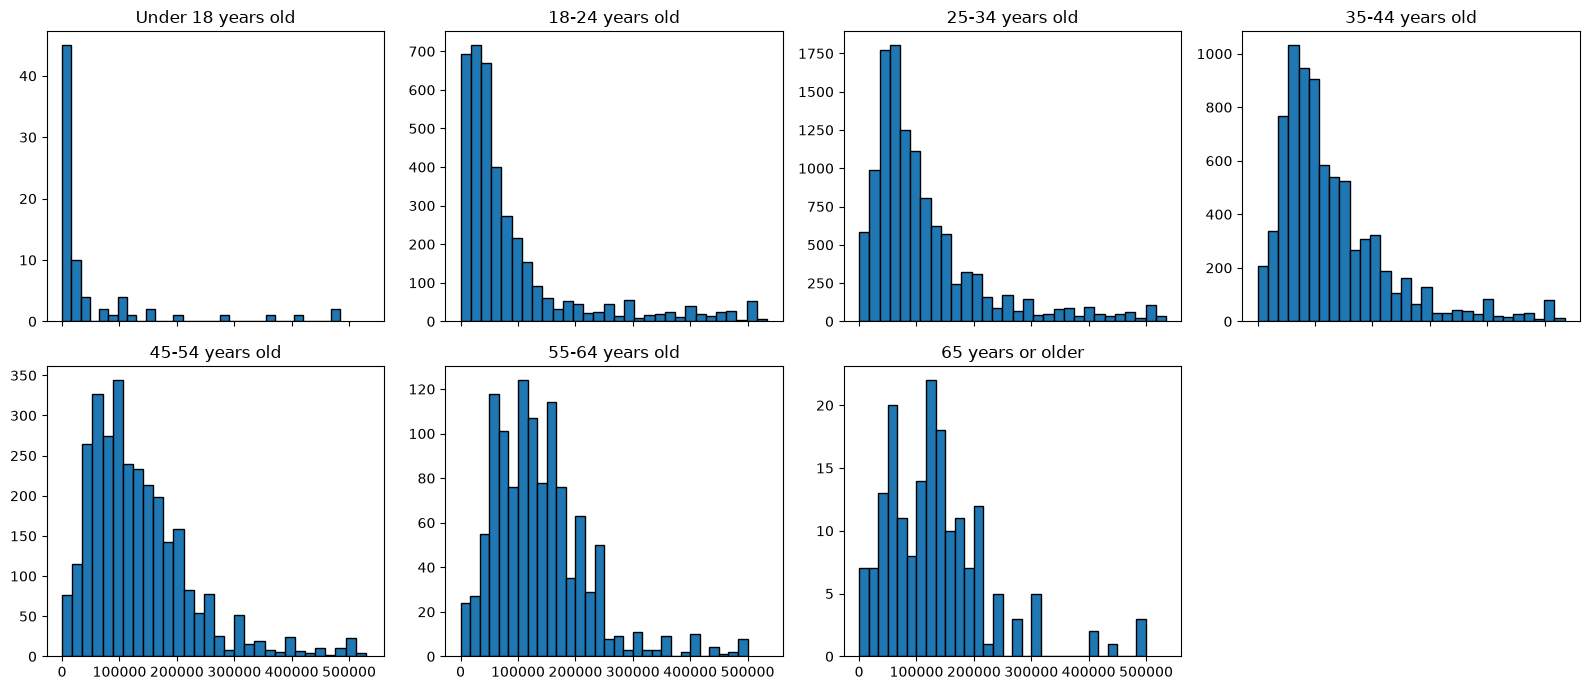

In [14]:
age_order = [
    'Under 18 years old', '18-24 years old', '25-34 years old',
    '35-44 years old', '45-54 years old', '55-64 years old',
    '65 years or older'
]
plot_df = filtered[filtered['Age'].isin(age_order)].dropna(subset=['CompTotal'])

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, age in zip(axes.flat, age_order):
    subset = plot_df.loc[plot_df['Age'] == age, 'CompTotal']
    ax.hist(subset, bins=30, edgecolor='black')
    ax.set_title(age)
for ax in axes.flat[len(age_order):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

**2.2 Histogram of TimeSearching for Different Age Groups**


Objective: Use a histogram to explore the distribution of preferred work arrangements (`remote work`).


In [15]:
## Write your code here
filtered['TimeSearching'].value_counts()

TimeSearching
30-60 minutes a day           7024
15-30 minutes a day           4886
60-120 minutes a day          3321
Less than 15 minutes a day    1617
Over 120 minutes a day        1364
Name: count, dtype: int64

In [16]:
time_order = [
    'Less than 15 minutes a day',
    '15-30 minutes a day',
    '30-60 minutes a day',
    '60-120 minutes a day',
    'Over 120 minutes a day'
]

plot_df2 = filtered[filtered['Age'].isin(age_order)].dropna(subset=['TimeSearching'])
plot_df2 = plot_df2[plot_df2['TimeSearching'].isin(time_order)]

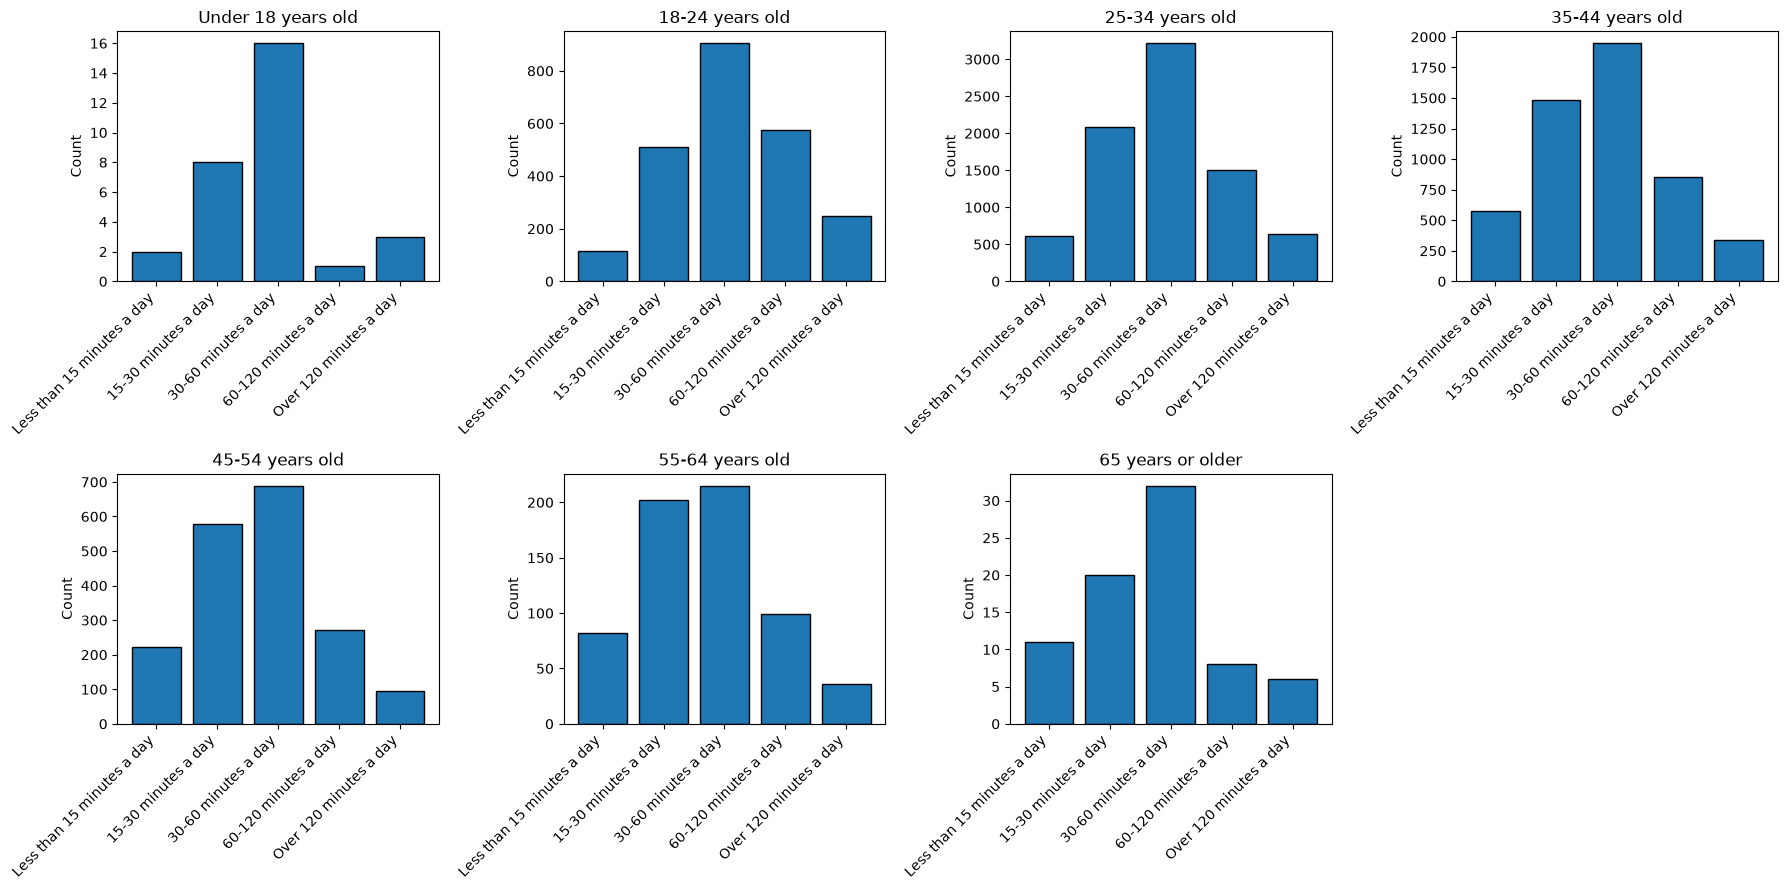

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for ax, age in zip(axes, age_order):
    counts = (plot_df2.loc[plot_df2['Age'] == age, 'TimeSearching']
              .value_counts()
              .reindex(time_order, fill_value=0))
    ax.bar(range(len(time_order)), counts.values, edgecolor='black')
    ax.set_xticks(range(len(time_order)))
    ax.set_xticklabels(time_order, rotation=45, ha='right')
    ax.set_title(f'{age}')
    ax.set_ylabel('Count')

axes[-1].axis('off')  # hide the 8th, unused chart

plt.tight_layout()
plt.show()

### 3. Visualizing the Composition of Data


**3.1 Histogram of Most Desired Databases (`DatabaseWantToWorkWith`)**


In [18]:
## Write your code here
db_split = (filtered['DatabaseWantToWorkWith']
            .dropna()
            .str.split(';')
            .explode()
            .str.strip())

top_5_db = db_split.value_counts().head(5)
top_5_db

DatabaseWantToWorkWith
PostgreSQL    11910
SQLite         6187
Redis          5441
MySQL          5002
MongoDB        4446
Name: count, dtype: int64

Text(0.5, 1.0, 'The Most Desired Database')

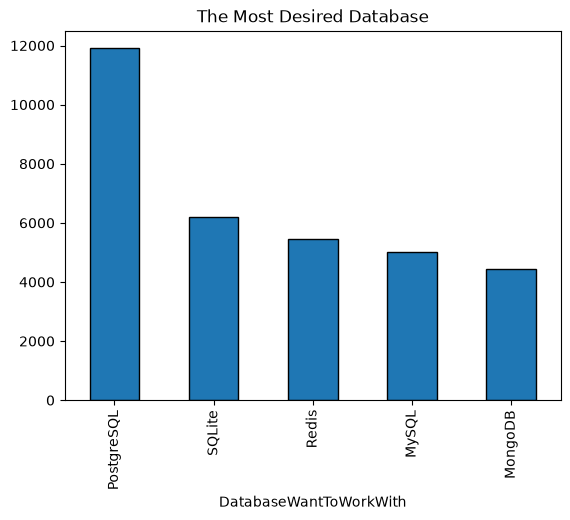

In [19]:
top_5_db.plot(kind='bar',edgecolor='black')
plt.title("The Most Desired Database")

**3.2 Histogram of Preferred Work Locations (`RemoteWork`)**


Text(0.5, 1.0, 'Distribution of Preferred Work Arrangements')

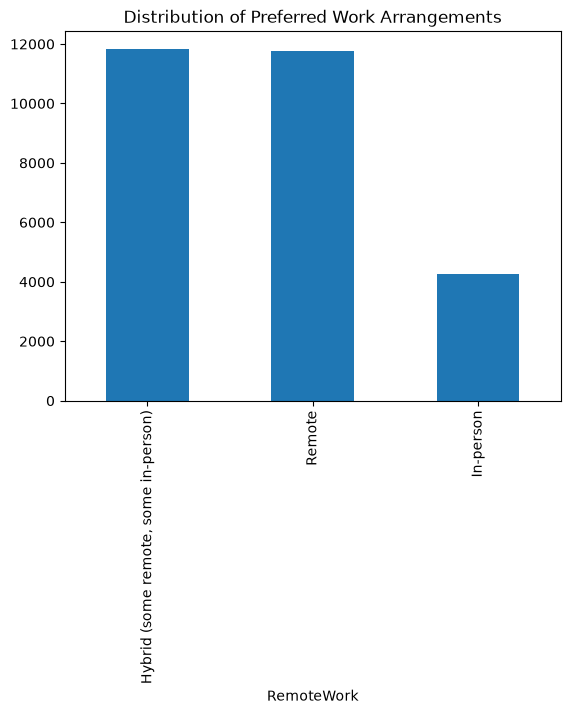

In [20]:
filtered['RemoteWork'].value_counts().plot(kind='bar')
plt.title('Distribution of Preferred Work Arrangements')

### 4. Visualizing Comparison of Data


**4.1 Histogram of Median CompTotal for Ages 45 to 60**


Objective: Plot the histogram for `CompTotal` within the age group 45 to 60 to analyze compensation distribution among mid-career respondents.


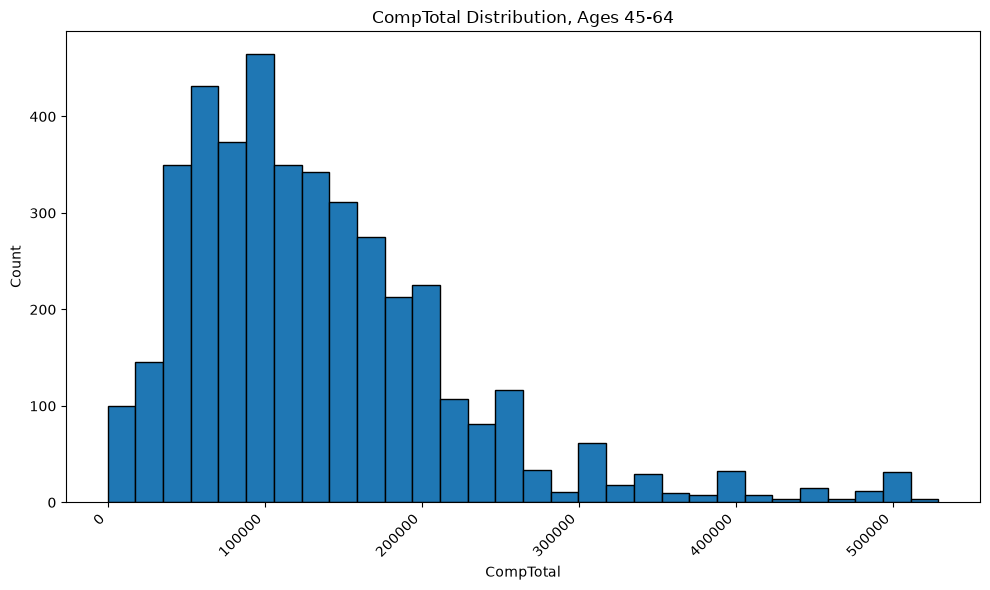

In [21]:
older = filtered[filtered['Age'].isin(['45-54 years old', '55-64 years old'])].dropna(subset=['CompTotal'])
plt.figure(figsize=(10, 6))
plt.hist(older['CompTotal'], bins=30, edgecolor='black')
plt.xticks(rotation=45, ha='right')
plt.xlabel('CompTotal')
plt.ylabel('Count')
plt.title(f'CompTotal Distribution, Ages 45-64')
plt.tight_layout()
plt.show()

**4.2 Histogram of Job Satisfaction (`JobSat`) by YearsCodePro**


Objective: Plot the histogram for `JobSat` scores based on respondents' years of professional coding experience.


In [22]:
## Write your code here
## Write your code here
mappings = {
    'Less than 1 year': 0.5,  
    'More than 50 years': 51 
}

filtered['YearsCodePro_Numeric'] = (
    filtered['YearsCodePro']
    .replace(mappings)
    .astype(float)
)

In [23]:
filtered['YearsCodePro_Numeric'].value_counts()

YearsCodePro_Numeric
3.0     2053
2.0     2019
10.0    1930
5.0     1915
4.0     1687
6.0     1621
8.0     1533
7.0     1523
1.0     1126
12.0    1042
15.0     928
9.0      898
20.0     874
0.5      831
11.0     783
13.0     651
14.0     636
16.0     599
25.0     534
18.0     501
17.0     487
24.0     351
30.0     336
19.0     316
22.0     295
23.0     287
26.0     252
28.0     217
21.0     217
27.0     211
35.0     148
32.0     118
29.0     114
34.0      98
40.0      94
38.0      84
33.0      71
31.0      66
36.0      61
37.0      53
45.0      33
39.0      32
42.0      29
41.0      22
43.0      20
44.0      17
51.0      17
46.0      12
48.0       9
50.0       8
49.0       4
47.0       4
Name: count, dtype: int64

In [25]:
bins = [-0.1, 2, 5, 10, 20, 52]
labels = ['< 2 years', '2-5 years', '6-10 years', '11-20 years', '20+ years']
filtered['YearsCodePro_Range'] = pd.cut(filtered['YearsCodePro_Numeric'], bins=bins, labels=labels)

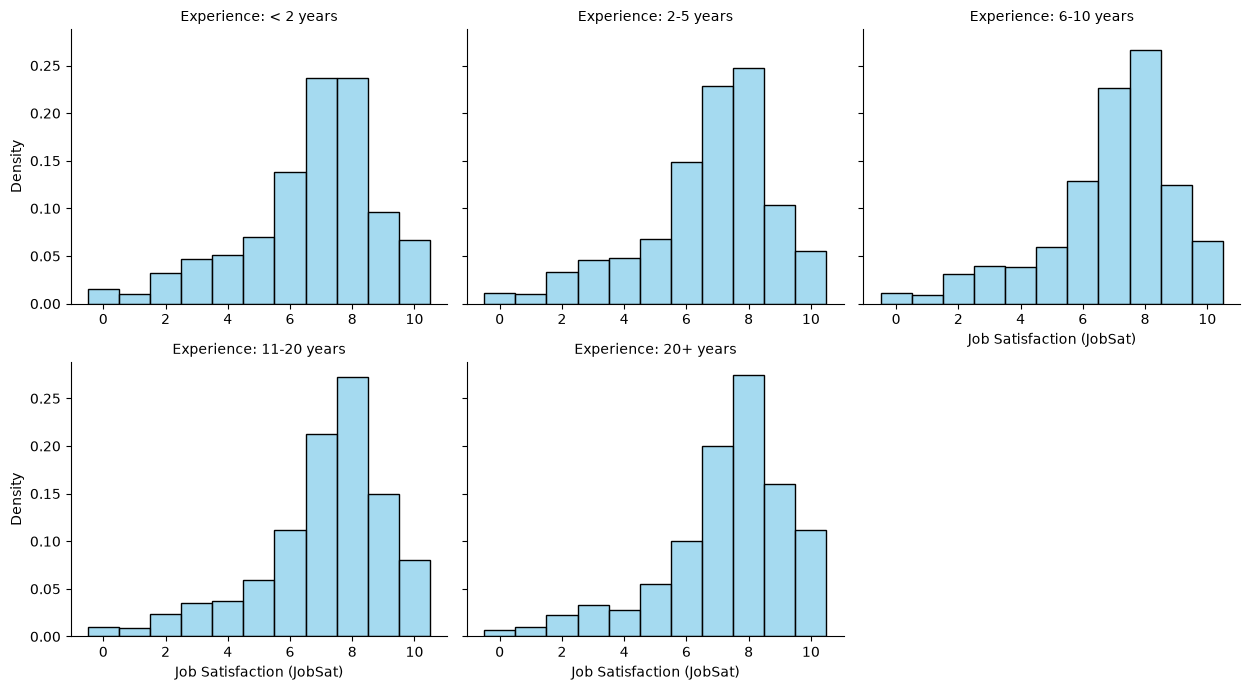

In [26]:
g = sns.FacetGrid(
    data=filtered, 
    col="YearsCodePro_Range", 
    col_wrap=3, 
    height=3.5, 
    aspect=1.2,
    sharex=False
)
g.map_dataframe(
    sns.histplot, 
    x="JobSat", 
    discrete=True,      
    stat="density",    
    color="skyblue", 
    edgecolor="black"
)

# Set axes titles
g.set_axis_labels("Job Satisfaction (JobSat)", "Density")
g.set_titles(col_template="Experience: {col_name}")

plt.tight_layout()
plt.show()

### Final step: Close the database connection


Once you've completed the lab, make sure to close the connection to the SQLite database:



In [27]:
conn.close()

### Summary


In this lab, you used histograms to visualize various aspects of the dataset, focusing on:

- Distribution of compensation, coding experience, and work hours.

- Relationships in compensation across age groups and work status.

- Composition of data by desired databases and work environments.

- Comparisons of job satisfaction across years of experience.

Histograms helped reveal patterns and distributions in the data, enhancing your understanding of developer demographics and preferences.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
